# Prueba 01 (Modelo HAHM)

In [1]:
%load_ext autoreload
%autoreload 2

In [48]:
import pandas as pd
import numpy as np
import UpROOT.io as io
import UpROOT.io_parquet as parq
import UpROOT.config as conf
import UpROOT.plotting.delphes as pt
import UpROOT.pipelines.delphes as pl

In [49]:
ANALYSIS = 'dp01'
cfg = conf.CONFIGURATIONS[ANALYSIS]
DATASET = cfg['raw_dataset']
PDATASET = cfg['flat_dataset']
(root_path,) = conf.ROOT_FILES[PDATASET]
PLOT_DATA = cfg['plot_data']
TARGET_MASS = None
MASS_RANGE = cfg['mass_range']
FIT_WINDOW = cfg['fit_window']

# Partícula a estudiar (código PDG/Status en Pythia/MadGraph)
PARTICLE_PID = 1023
PARTICLE_STATUS = None
PARTICLE_LABEL = "Z'"
TAG = f'pid{PARTICLE_PID}_st{PARTICLE_STATUS}'

MIN_MUON_PT = 0.0
ETA_RANGE = (2.0, 5.0)

plot_options = {
    'save': True,
    'data': PLOT_DATA,
    'output_dir': None
}
particle_options = {**plot_options, 'label': PARTICLE_LABEL}

In [50]:
# cut = '(PID == 1023) & (Status == 23)' # Código del fotón oscuro zp
sel = dict(dataset=PDATASET, pids=PARTICLE_PID, statuses=PARTICLE_STATUS)
BRANCHES = (
    'source_file_id',
    'event_id',
    'object_index',
    'PID',
    'Status',
    'Mass',
    'E',
    'Px',
    'Py',
    'Pz',
    'P',
    'PT',
    'Eta',
    'Phi',
)

In [51]:
df_events = io.load_dataframe(
    branches=['source_file_id', 'event_id', 'n_Electron', 'n_Jet', 'n_Muon', 'n_Particle'],
    dataset=PDATASET,
    tree_path='Events',
)
df_events.head()

Archivo: hahm01_pandas.root
Árbol seleccionado: Events
Total de eventos: 250,000 eventos


,source_file_id,event_id,n_Electron,n_Jet,n_Muon,n_Particle
0,0,0,0,0,0,595
1,0,1,0,0,0,768
2,0,2,0,0,0,189
3,0,3,0,0,0,2436
4,0,4,0,0,0,1655


In [52]:
particle_parquet = parq.export_particles(
    root_path, 
    columns=BRANCHES, 
    **sel,
    overwrite=True
)
particle_parquet

WindowsPath('C:/Users/mario/Documents/PF/MadGraph/assets/parquet/hahm01_p_pid1023.parquet')

In [53]:
print(f'{parq.parquet_rows(**sel):,} partículas seleccionadas')
parq.read_parquet(
    columns=['event_id', 'PID', 'Status', 'Mass', 'PT', 'Eta', 'Phi'],
    rows=5,
    **sel
)

2,722,378 partículas seleccionadas


,event_id,PID,Status,Mass,PT,Eta,Phi
0,0,1023,23,20.0,9.945009,3.755843,2.705823
1,0,1023,23,20.0,9.945009,3.466074,-0.435770
2,0,1023,44,20.0,4.031088,4.761654,-3.012913
3,0,1023,44,20.0,14.935367,3.162511,-0.544231
4,0,1023,44,20.0,3.490932,4.893651,-3.091504


In [54]:
df_particle = parq.read_parquet(**sel)
analysis = pl.prepare_particle_analysis(
    df_particle,
    pid=PARTICLE_PID,
    status=PARTICLE_STATUS,
    events=df_events
)

In [55]:
df_jet = io.load_dataframe(
    dataset=PDATASET,
    tree_path='Jets',
    branches=['event_id', 'object_index', 'PT', 'Eta', 'Phi', 'Mass', 'BTag']
)
df_jet.head()

Archivo: hahm01_pandas.root
Árbol seleccionado: Jets
Total de eventos: 14,153 eventos


,event_id,object_index,PT,Eta,Phi,Mass,BTag
0,14,0,61.487030,3.052444,-1.646453,10.360204,0
1,18,0,29.117243,3.955630,0.453304,3.902158,0
2,20,0,31.960789,2.291435,-2.881316,5.857267,0
3,35,0,34.580399,3.731804,-0.135639,7.535460,0
4,47,0,24.833134,2.825736,-2.939931,5.642444,0


In [56]:
df_met = io.load_dataframe(
    dataset=PDATASET,
    tree_path='MissingET',
    branches=['event_id', 'MET', 'Eta', 'Phi']
)
df_met.head()

Archivo: hahm01_pandas.root
Árbol seleccionado: MissingET
Total de eventos: 250,000 eventos


,event_id,MET,Eta,Phi
0,0,11.048661,-5.085212,-1.191543
1,1,6.888885,-4.757220,-0.264702
2,2,2.902069,-4.389211,-2.566138
3,3,12.245849,-5.543507,-3.046134
4,4,24.237535,-4.471204,3.120107


In [57]:
analysis = pl.prepare_particle_analysis(
    df_particle,
    pid=PARTICLE_PID,
    status=PARTICLE_STATUS,
    events=df_events
)
particles = analysis['particles']
pairs = analysis['particle_pairs']
summary = analysis['summary']
pairs.head()

,source_file_id,event_id,n_particles,p1_index,p1_pid,p1_status,p1_mass,p1_e,p1_px,p1_py,...,pair_px,pair_py,pair_pz,pair_mass,pair_pt,pair_eta,pair_phi,pair_rapidity,pair_delta_phi,pair_delta_r
0,0,35,2,360,1023,1,20.0,261.649750,-62.758327,-32.457191,...,-36.720314,12.251377,-523.322525,124.989368,38.710176,-3.298608,2.819566,-2.094595,2.575465,2.603611
1,0,2333,2,299,1023,1,20.0,271.950470,47.677509,13.399639,...,21.392553,-19.439678,-310.316483,124.997396,28.905751,-3.068861,-0.737608,-1.616626,2.519768,2.920816
2,0,2682,2,602,1023,1,20.0,118.221870,77.033089,-35.216587,...,82.111365,23.991493,113.692730,125.007141,85.544538,1.096038,0.284269,0.693604,-1.914029,1.937643
3,0,3301,2,764,1023,1,20.0,229.728760,-58.054588,-12.336713,...,-4.995987,-3.576262,329.013893,124.998423,6.144065,4.673848,-2.520323,1.694093,-3.095838,3.149386
4,0,4888,2,854,1023,1,20.0,518.475891,-13.998868,71.227226,...,11.384791,34.861954,-1150.963867,124.999654,36.673823,-4.139693,1.255147,-2.875092,2.726262,2.816460


In [58]:
particles.head()

,source_file_id,event_id,object_index,PID,Status,Mass,E,Px,Py,Pz,P,PT,Eta,Phi
0,0,0,3,1023,23,20.0,213.729355,-9.015602,4.197872,212.559006,212.791534,9.945009,3.755843,2.705823
1,0,0,4,1023,23,20.0,160.579559,9.015602,-4.197872,159.018539,159.329208,9.945009,3.466074,-0.435770
2,0,0,8,1023,44,20.0,236.560242,-3.997760,-0.517290,235.678802,235.713272,4.031088,4.761654,-3.012913
3,0,0,9,1023,44,20.0,177.904099,12.777593,-7.732936,176.144272,176.776321,14.935367,3.162511,-0.544231
4,0,0,39,1023,44,20.0,233.784973,-3.486554,-0.174784,232.901749,232.927917,3.490932,4.893651,-3.091504


In [59]:
display(pd.Series(summary, name='resumen'))

pid                                                                               [1023]
status_filter                                                                       None
n_total_events                                                                    250000
n_particle_rows_all_statuses                                                     2722378
n_particle_rows_selected                                                         2722378
n_events_with_particle                                                            250000
n_events_with_exactly_two                                                            406
fraction_total_events_with_particle                                                  1.0
multiplicity_counts                    {2: 406, 4: 11423, 6: 27410, 8: 40524, 10: 503...
status_counts                                       {1: 500000, 23: 499188, 44: 1723190}
mass_mean_gev                                                                       20.0
mass_std_gev         

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\particle_multiplicity_pid1023_stNone.png.


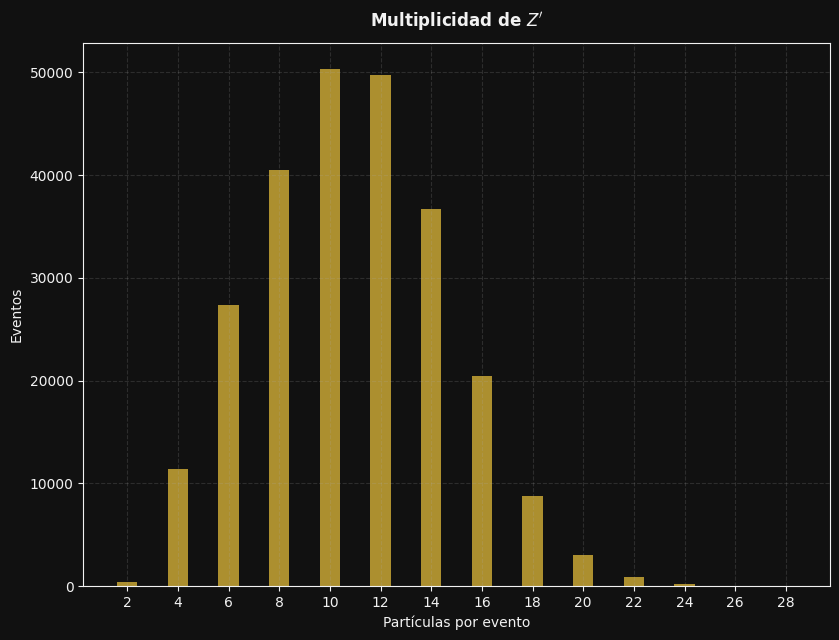

(<Figure size 850x650 with 1 Axes>,
 <Axes: title={'center': "Multiplicidad de $Z'$"}, xlabel='Partículas por evento', ylabel='Eventos'>)

In [60]:
pt.plot_mediator_multiplicity(
    particles,
    filename=f'particle_multiplicity_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\particle_pair_kinematics_pid1023_stNone.png.


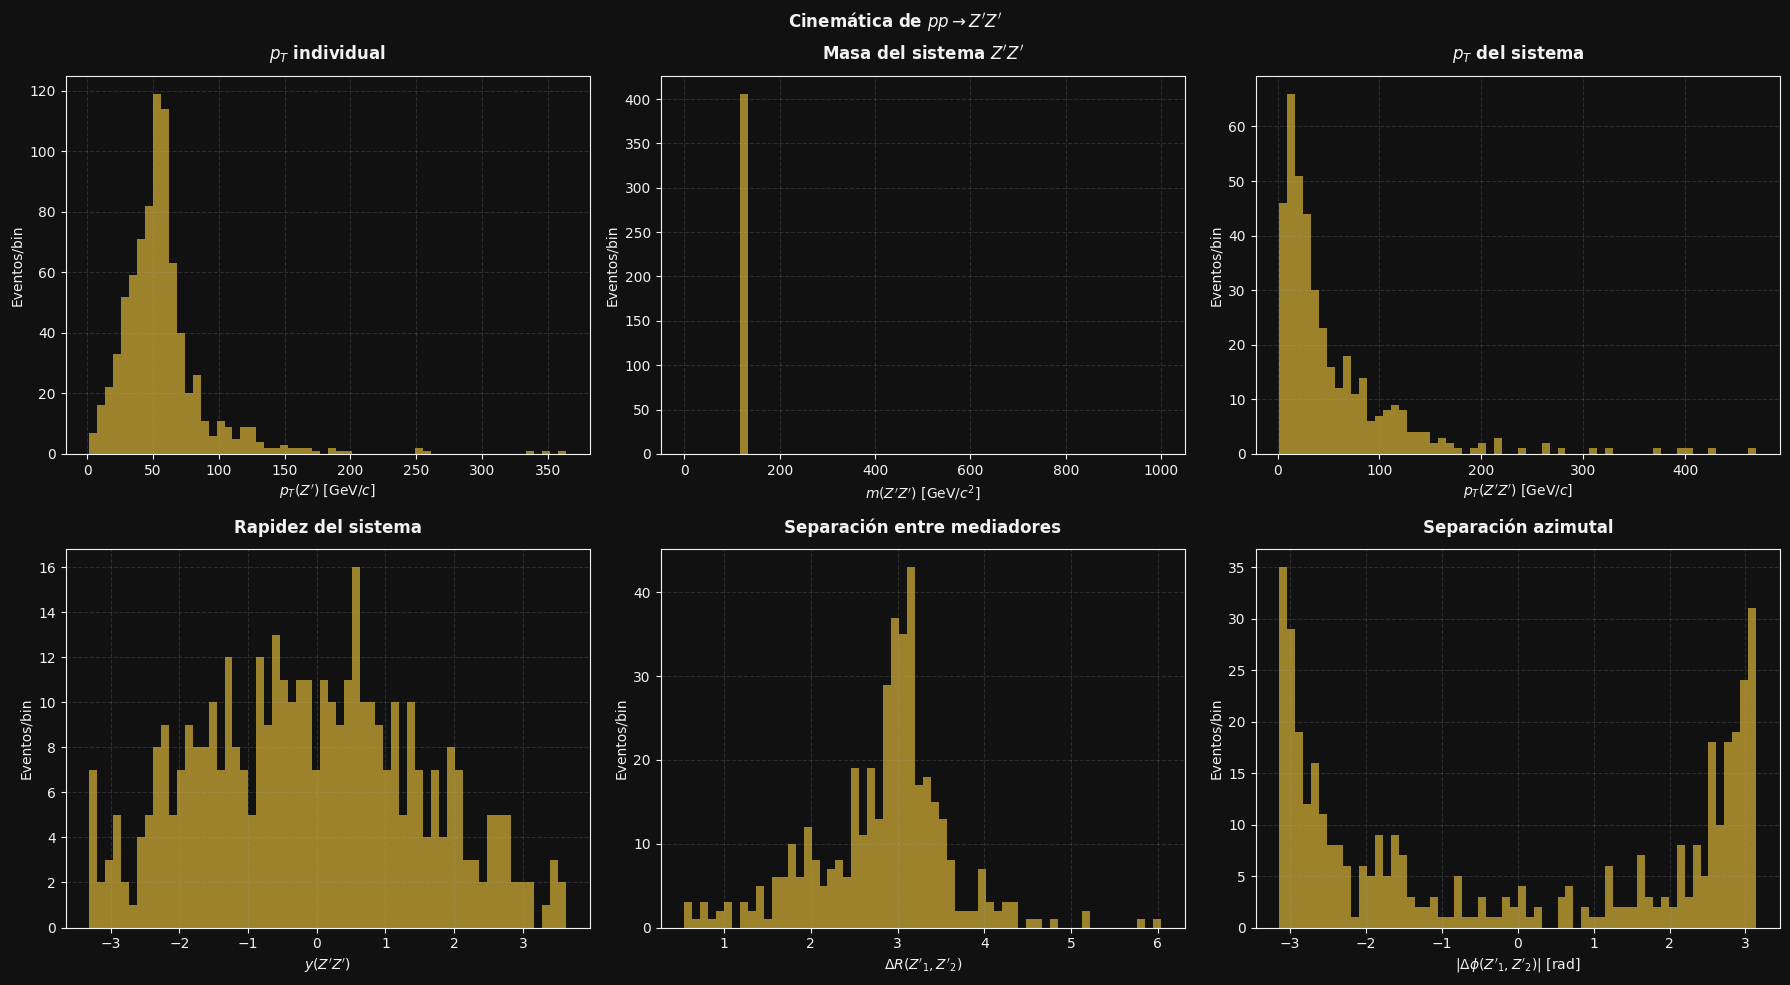

(<Figure size 1800x1000 with 6 Axes>,
 array([[<Axes: title={'center': '$p_T$ individual'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Eventos/bin'>,
         <Axes: title={'center': "Masa del sistema $Z'Z'$"}, xlabel="$m(Z'Z')$ [GeV/$c^2$]", ylabel='Eventos/bin'>,
         <Axes: title={'center': '$p_T$ del sistema'}, xlabel="$p_T(Z'Z')$ [GeV/$c$]", ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'Rapidez del sistema'}, xlabel="$y(Z'Z')$", ylabel='Eventos/bin'>,
         <Axes: title={'center': 'Separación entre mediadores'}, xlabel="$\\Delta R(Z'_1,Z'_2)$", ylabel='Eventos/bin'>,
         <Axes: title={'center': 'Separación azimutal'}, xlabel="$|\\Delta\\phi(Z'_1,Z'_2)|$ [rad]", ylabel='Eventos/bin'>]],
       dtype=object))

In [61]:
pt.plot_mediator_pair_observables(
    pairs,
    bins=60,
    pair_mass_range=(0.0, 1000.0),
    filename=f'particle_pair_kinematics_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\event_multiplicities.png.


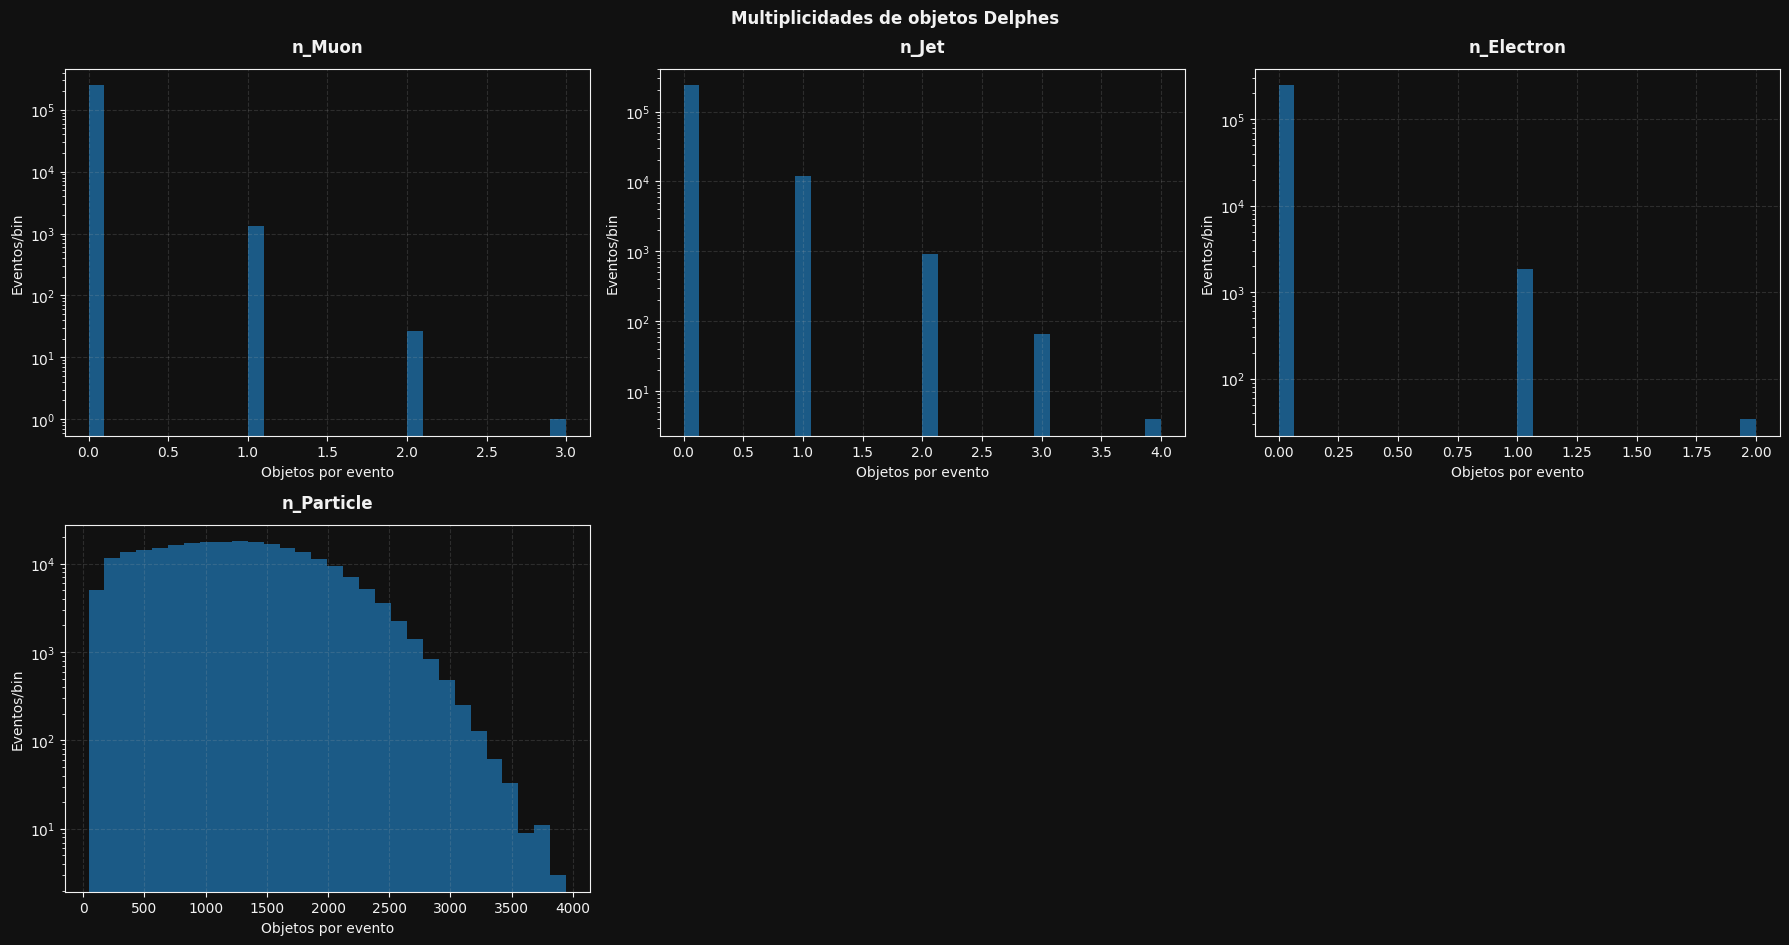

(<Figure size 1800x960 with 6 Axes>,
 array([[<Axes: title={'center': 'n_Muon'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Jet'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Electron'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'n_Particle'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: >, <Axes: >]], dtype=object))

In [62]:
pt.plot_event_multiplicities(
    df_events,
    filename='event_multiplicities',
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\zp_kinematics.png.


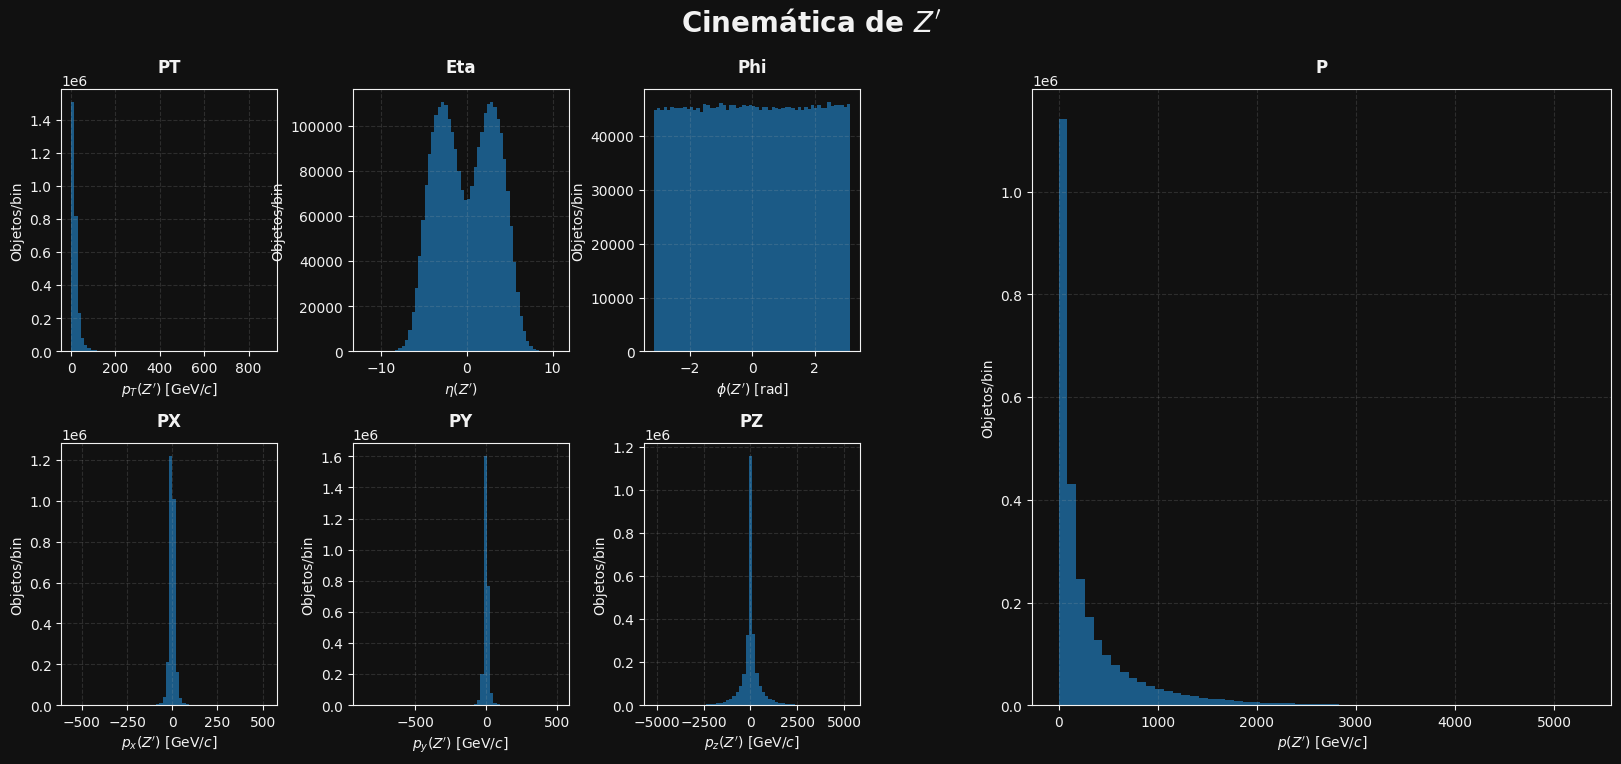

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel="$\\eta(Z')$", ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel="$\\phi(Z')$ [rad]", ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel="$p_x(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel="$p_y(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel="$p_z(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel="$p(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>})

In [63]:
pt.plot_particle_kinematics(
    particles, 
    bins=60, 
    filename="zp_kinematics",
    **particle_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\particle_kinematics_pid1023_stNone_split.png.


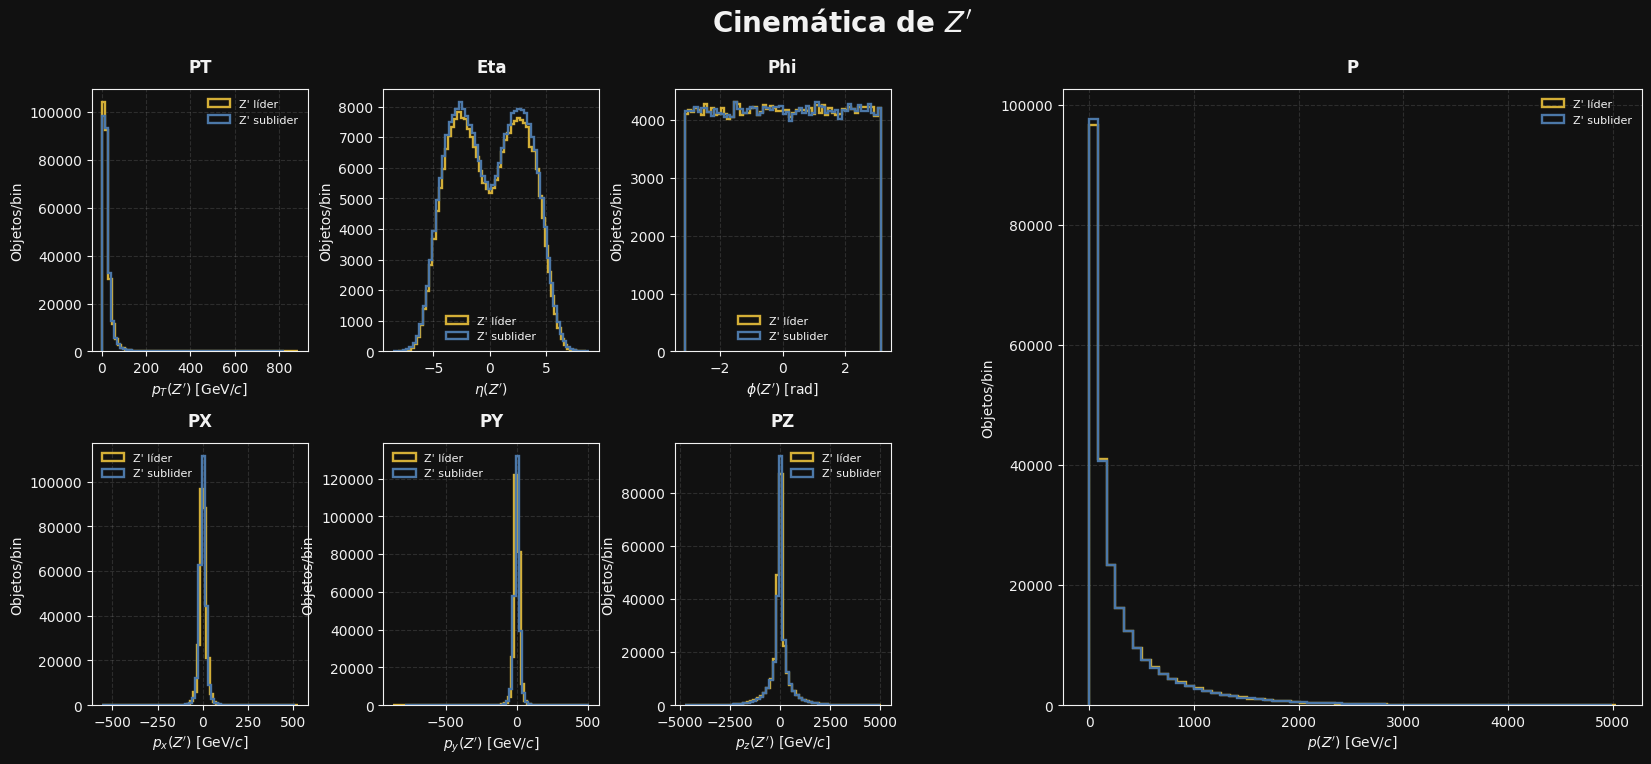

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel="$\\eta(Z')$", ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel="$\\phi(Z')$ [rad]", ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel="$p_x(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel="$p_y(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel="$p_z(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel="$p(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>})

In [64]:
pt.plot_particle_kinematics(
    particles, 
    bins=60,
    split_rank=True,
    filename=f"particle_kinematics_{TAG}_split",
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\particle_mass_pid1023_stNone.png.


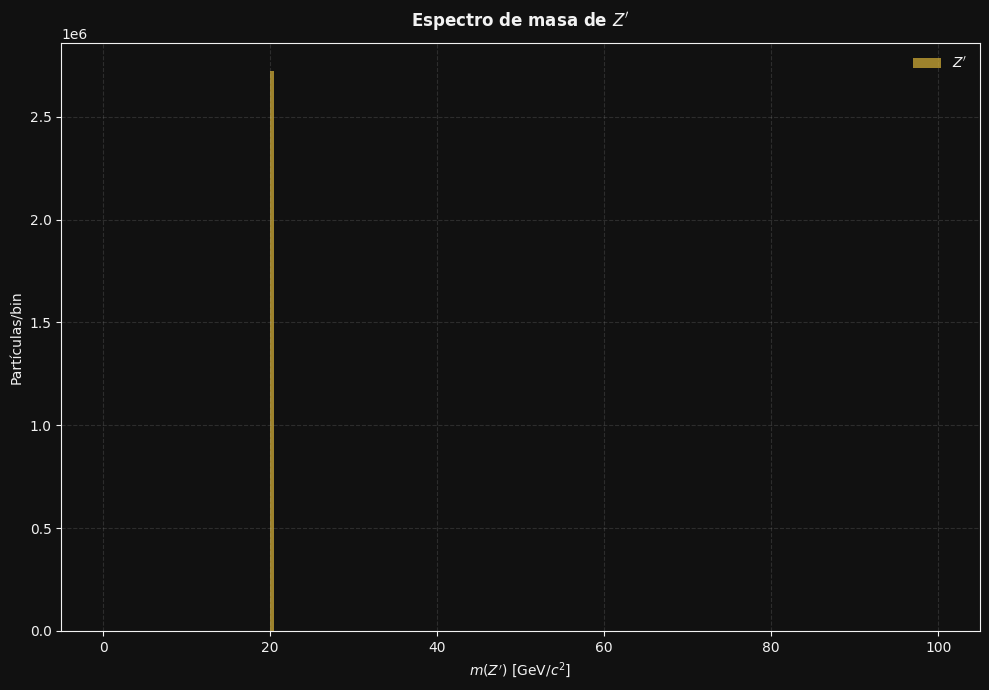

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': "Espectro de masa de $Z'$"}, xlabel="$m(Z')$ [GeV/$c^2$]", ylabel='Partículas/bin'>)

In [65]:
pt.plot_particle_mass(
    particles,
    bins=200,
    mass_range=MASS_RANGE,
    log_x=False,
    log_y=False,
    filename=f'particle_mass_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\particle_pair_mass_pid1023_stNone.png.


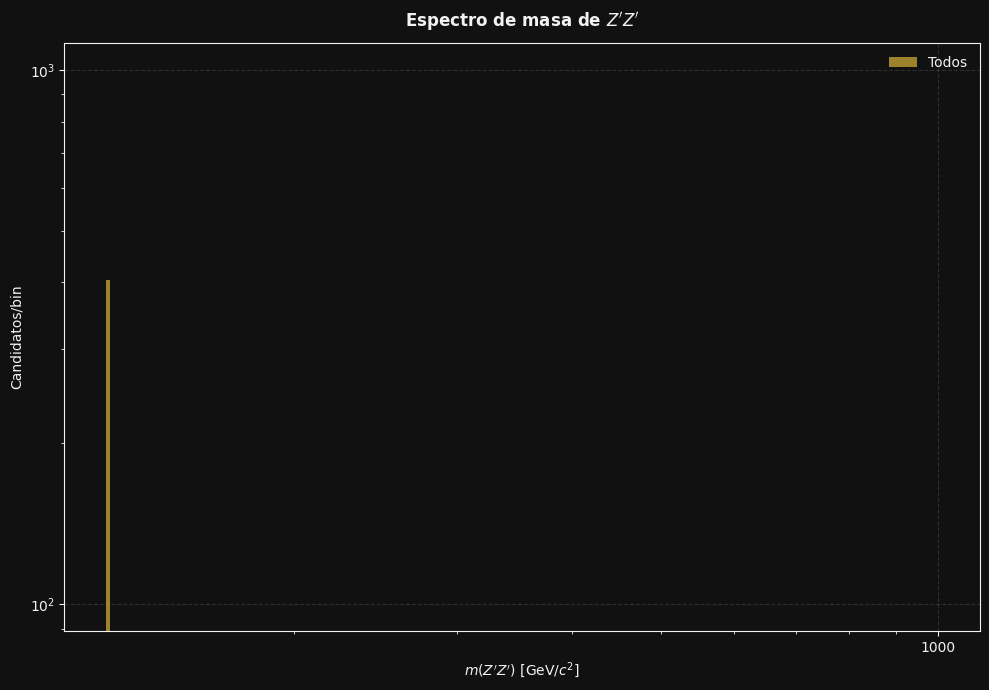

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': "Espectro de masa de $Z'Z'$"}, xlabel="$m(Z'Z')$ [GeV/$c^2$]", ylabel='Candidatos/bin'>)

In [66]:
pt.plot_particle_pair_mass(
    pairs,
    bins=200,
    log_x=True,
    log_y=True,
    mass_range=(0.0, 1000.0),
    filename=f'particle_pair_mass_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c01\jet_kinematics_pid1023_stNone.png.


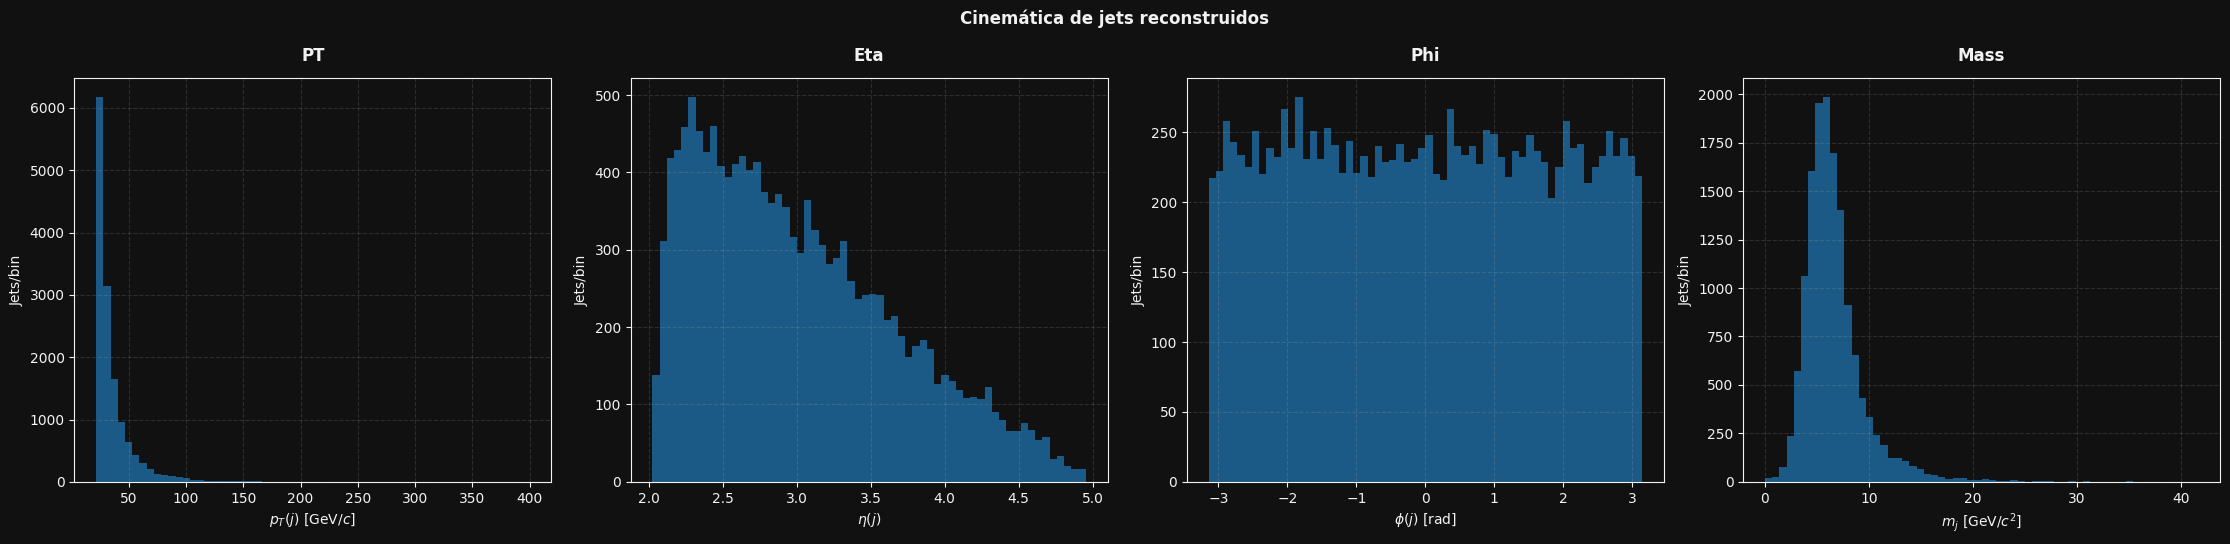

(<Figure size 2240x550 with 4 Axes>,
 array([[<Axes: title={'center': 'PT'}, xlabel='$p_T(j)$ [GeV/$c$]', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Eta'}, xlabel='$\\eta(j)$', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Phi'}, xlabel='$\\phi(j)$ [rad]', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Mass'}, xlabel='$m_j$ [GeV/$c^2$]', ylabel='Jets/bin'>]],
       dtype=object))

In [67]:
pt.plot_jet_kinematics(
    df_jet,
    bins=60,
    filename=f'jet_kinematics_{TAG}',
    **plot_options
)